# Entropy Calculation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss.entropy import entropy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

## 2D Lattice

In [3]:
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Entropy

In [4]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])

    if "entropy" in mu_df.columns:
        entropy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        entropy_df = entropy(mu_df, e_k)
        entropy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
entropy_df

mu  iterations  converged      residual  \
distro n        k_BT   H_a                                                    
FD     0.010000 100.00 0.0 -529.350200          20       True  8.137874e-09   
       0.035359 100.00 0.0 -401.770506          23       True  1.583139e-08   
       0.060718 100.00 0.0 -346.402267          23       True  6.254147e-08   
       0.086077 100.00 0.0 -310.185179          22       True  1.685919e-09   
       0.111436 100.00 0.0 -283.029968          23       True  6.264613e-08   
...                                ...         ...        ...           ...   
SSL    0.897564 0.01   0.0    2.810296          17       True  5.297233e-08   
       0.922923 0.01   0.0    3.077111          23       True  2.783862e-08   
       0.948282 0.01   0.0    3.366265          23       True  8.989371e-08   
       0.973641 0.01   0.0    3.668974          23       True  4.617714e-08   
       0.999000 0.01   0.0    3.983881          25       True  5.561068e-08   

                             entropy  
distro n        k_BT   H_a            
FD     0.010000 100.00 0.0  0.062956  
       0.035359 100.00 0.0  0.177724  
       0.060718 100.00 0.0  0.271964  
       0.086077 100.00 0.0  0.354951  
       0.111436 100.00 0.0  0.430018  
...                              ...  
SSL    0.897564 0.01   0.0  0.624871  
       0.922923 0.01   0.0  0.643114  
       0.948282 0.01   0.0  0.660580  
       0.973641 0.01   0.0  0.677773  
       0.999000 0.01   0.0  0.694247  

[1000 rows x 5 columns]

#### $\frac{S} {k_B N} = f(n)$

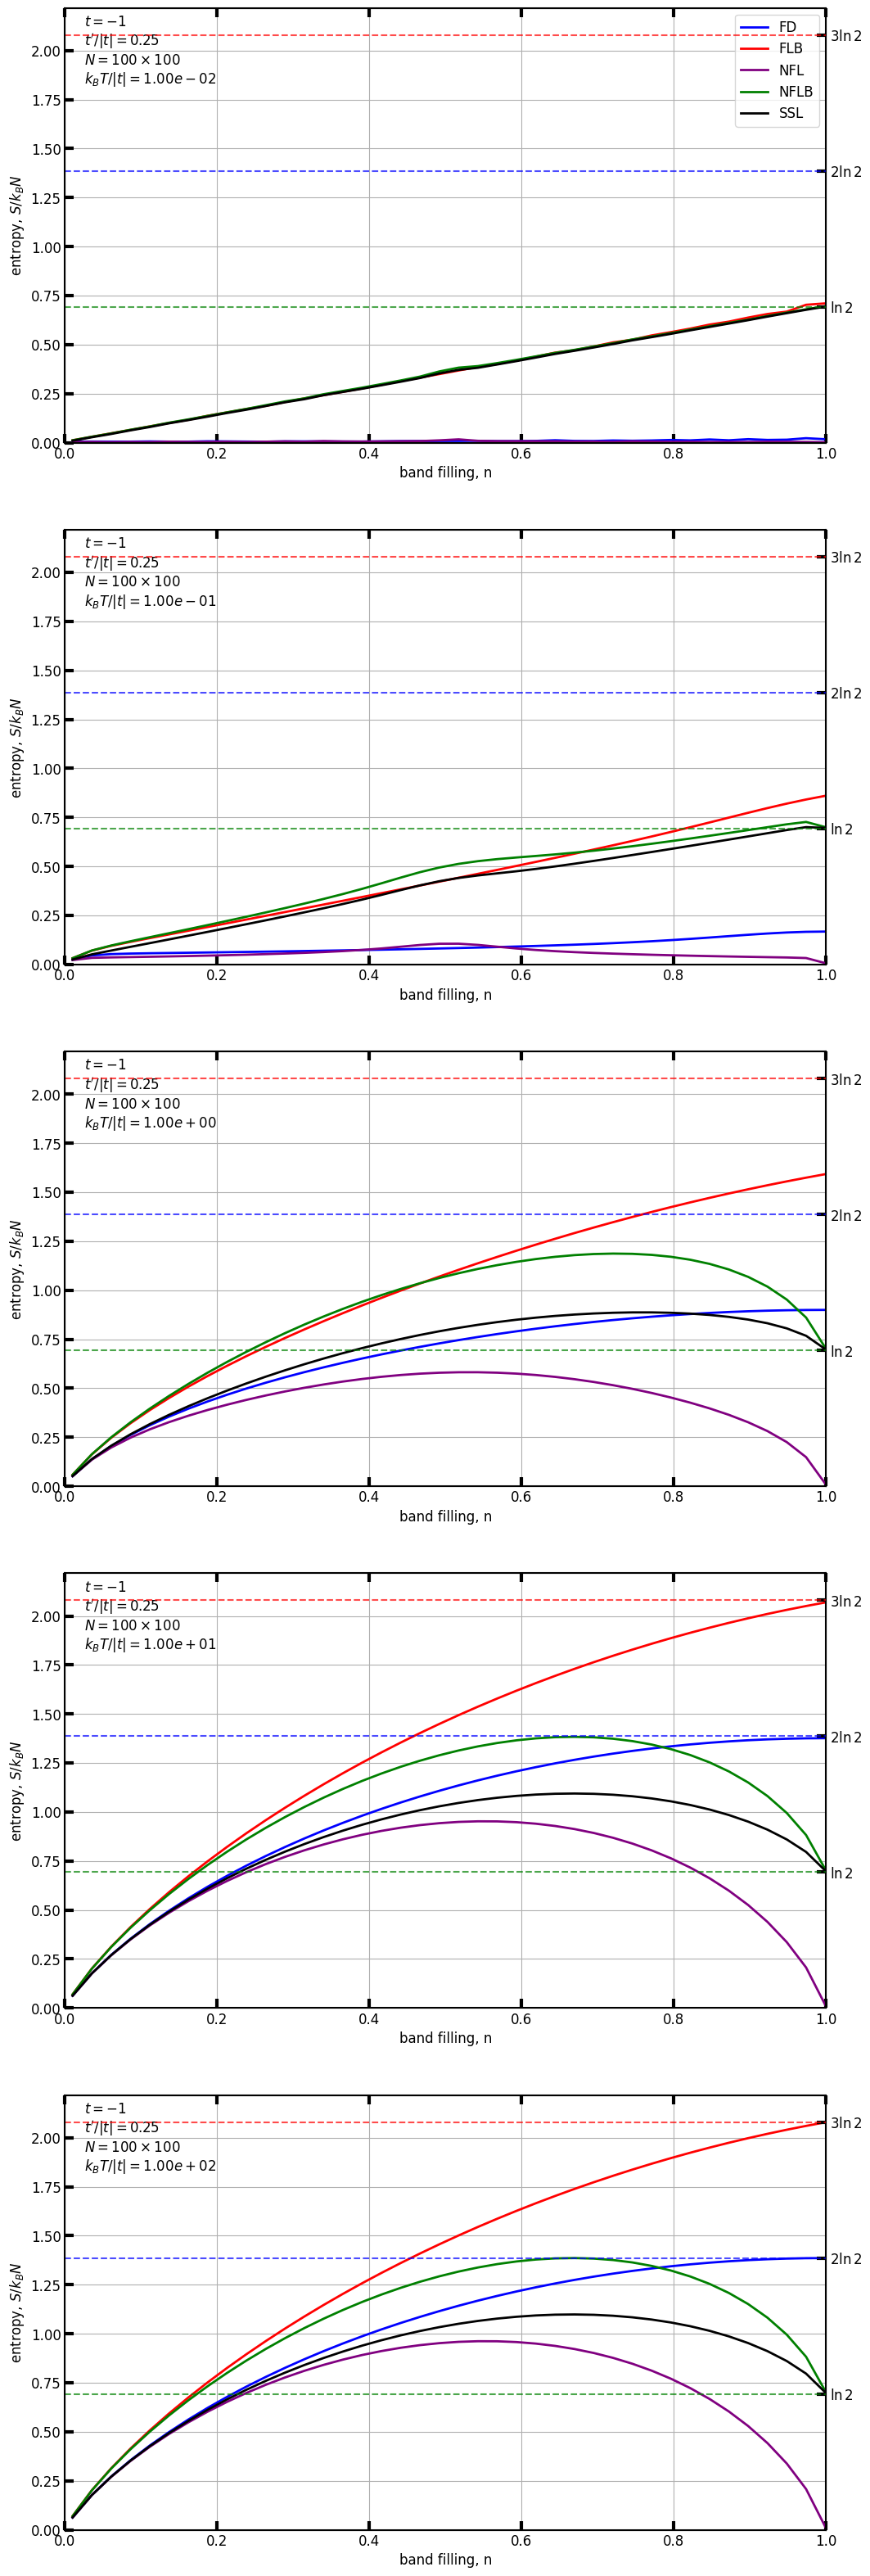

In [10]:
H_a_plot = H_a[0] 
beta_plot = 1/k_BT

# Plot
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=list(distro),
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=1,
    figsize=(12, 8),
    show_log_vals=True,
    ylims=(0, 2.5),
    xlims=(0, 1)
)
plt.show()

### $\frac{S} {k_B N} = f(k_BT)$


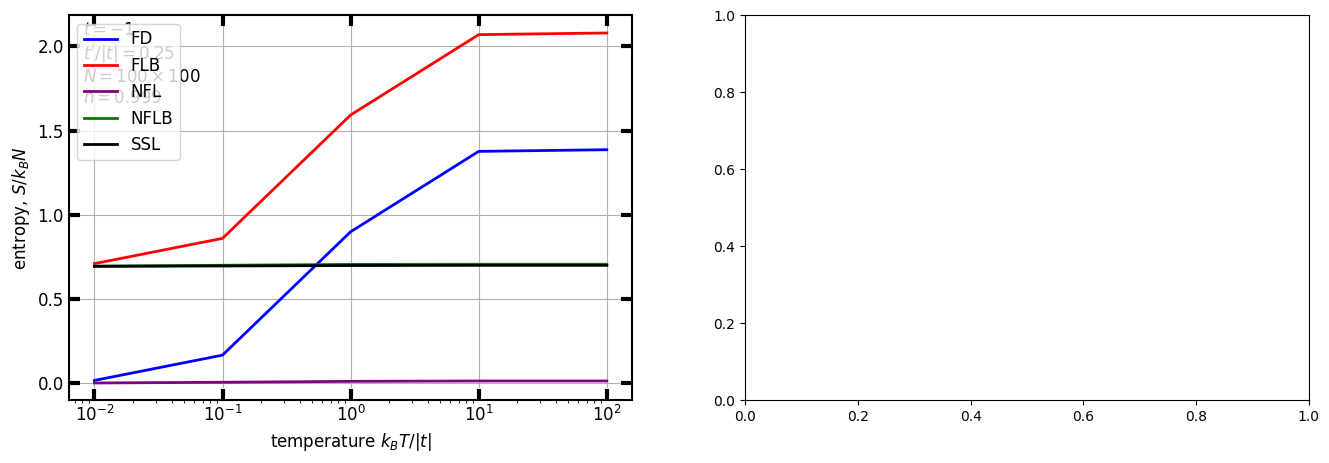

In [6]:
n_plot = [n[-1]]
H_a_plot = H_a[0]

# Plot
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="k_BT",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=list(distro),
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

#### $\frac{S} {k_B N} = f(H_a)$

/home/mateuszzx/Workspace/Python_Workspace/Spalek_Workspace/quantum-statistics-solver/tools/scientific_plot_v2.py:92: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale(xscale)


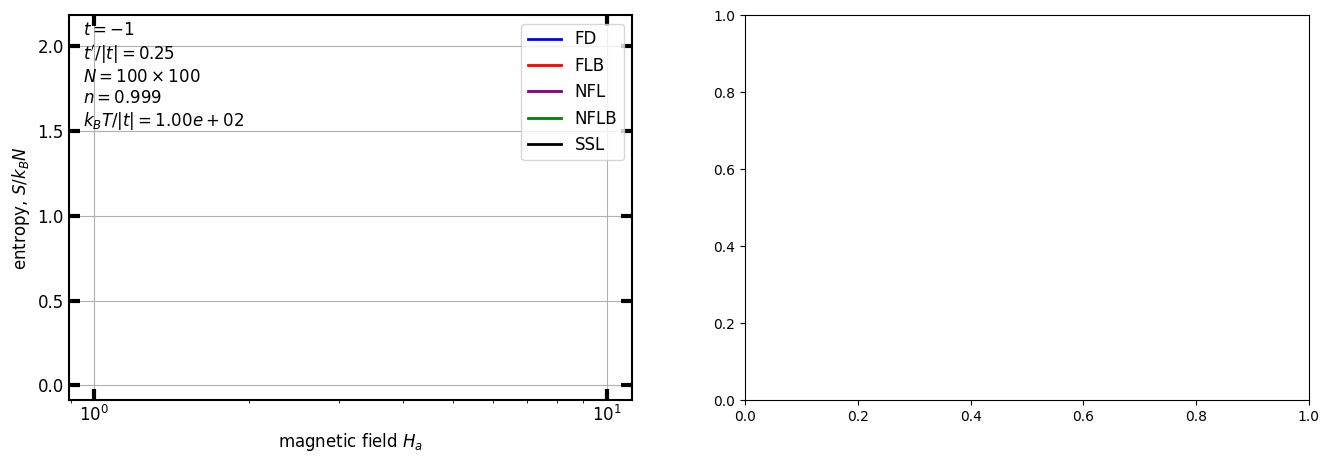

In [7]:
n_plot = [n[-1]]
beta_plot = 1/k_BT[-1]
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="H_a",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"beta": beta_plot},
    distros=list(distro),
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

#### $\frac{S} {k_B N} = f(n, k_BT)$

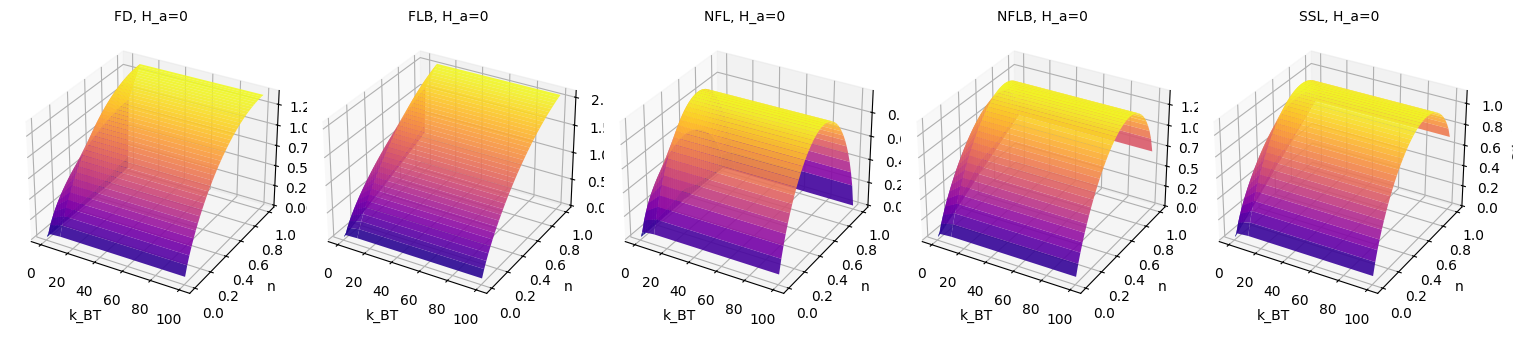

In [8]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
plotter.plot_3d_results(
    results=entropy_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a,     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="entropy",          # or "entropy" if you have calculated it
    distros=list(distro),
    # figsize=(15, 10)
)
plt.show()